# The Structure of Public Expenditure in Finland 1990-2024

This project examines what the Finnish public sector spends its money on and how the distribution of expenditure has changed over 1990-2024. Expenditure is measured relative to gross domestic product (GDP) so that different years are comparable.

**Main question:** How has the distribution of public expenditure across functions changed in Finland over 1990-2024, and which expenditure items have grown the most relative to GDP?

The project is divided into three parts: the first retrieves the data from the Statistics Finland API, the second looks at the development of the total level of expenditure, and the third compares changes in the different expenditure items.

### Data

The data is retrieved from the Statistics Finland PxWeb API: *General government expenditure by function* (StatFin, table 12a6), https://stat.fi/en/statistics/jmete. License: CC BY 4.0.

---

## 1. Retrieving the data

First, import the Python libraries needed in this project.

In [13]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

The data is retrieved from the Statistics Finland API. The query limits the data to the whole general government sector, total expenditure, and the ten main functions relative to GDP.

In [14]:
# Source: Statistics Finland, General government expenditure by function (StatFin 12a6), license CC BY 4.0

API_URL = "https://pxdata.stat.fi/PxWeb/api/v1/fi/StatFin/jmete/12a6.px"

QUERY = {
    "query": [
        {"code": "sektoriluokitus_7_20230101", "selection": {"filter": "item", "values": ["S13"]}},
        {"code": "taloustoimi_1_20180101", "selection": {"filter": "item", "values": ["OTES"]}},
        {"code": "julkisyht_teht_3_20010101", "selection": {"filter": "item",
            "values": ["SSS", "G01", "G02", "G03", "G04", "G05", "G06", "G07", "G08", "G09", "G10"]}},
        {"code": "contentscode", "selection": {"filter": "item", "values": ["jmete-bkt_suhde"]}}
    ],
    "response": {"format": "json"}
}

Retrieve the data. If something goes wrong, an error message is shown.

In [15]:
try:
    response = requests.post(API_URL, json=QUERY)
    data = response.json()
except Exception as error:
    print("Retrieving the data failed:", error)

Convert the retrieved data into a table. The API returns the column names in Finnish, so they are replaced with English names.

In [16]:
rows = []
for row in data["data"]:
    rows.append(row["key"] + row["values"])

columns = ["Sector", "Transaction", "Function", "Year", "Share of GDP, %"]

df = pd.DataFrame(rows, columns=columns)
df

,Sector,Transaction,Function,Year,"Share of GDP, %"
0,S13,OTES,SSS,1990,47.9
1,S13,OTES,SSS,1991,56.7
2,S13,OTES,SSS,1992,61.8
3,S13,OTES,SSS,1993,64.1
4,S13,OTES,SSS,1994,62.5
...,...,...,...,...,...
380,S13,OTES,G10,2020,25.9
381,S13,OTES,G10,2021,25.1
382,S13,OTES,G10,2022,23.8
383,S13,OTES,G10,2023,25.6


The Sector and Transaction columns are removed because they have the same value on every row (S13 and OTES). In addition, the function codes are converted into names and the values into numbers so that they can be used in calculations.

In [17]:
functions = {
    "SSS": "Total",
    "G01": "General public services",
    "G02": "Defence",
    "G03": "Public order and safety",
    "G04": "Economic affairs",
    "G05": "Environmental protection",
    "G06": "Housing and community amenities",
    "G07": "Health",
    "G08": "Recreation and culture",
    "G09": "Education",
    "G10": "Social protection"
}

df = df.drop(columns=["Sector", "Transaction"])
df["Function"] = df["Function"].map(functions)
df["Year"] = df["Year"].astype(int)
df["Share of GDP, %"] = df["Share of GDP, %"].astype(float)
df

,Function,Year,"Share of GDP, %"
0,Total,1990,47.9
1,Total,1991,56.7
2,Total,1992,61.8
3,Total,1993,64.1
4,Total,1994,62.5
...,...,...,...
380,Social protection,2020,25.9
381,Social protection,2021,25.1
382,Social protection,2022,23.8
383,Social protection,2023,25.6


The table is pivoted so that years are rows and functions are columns. This way the whole dataset can be seen at a glance. The colours highlight larger values: the darker the cell, the larger the share of GDP.

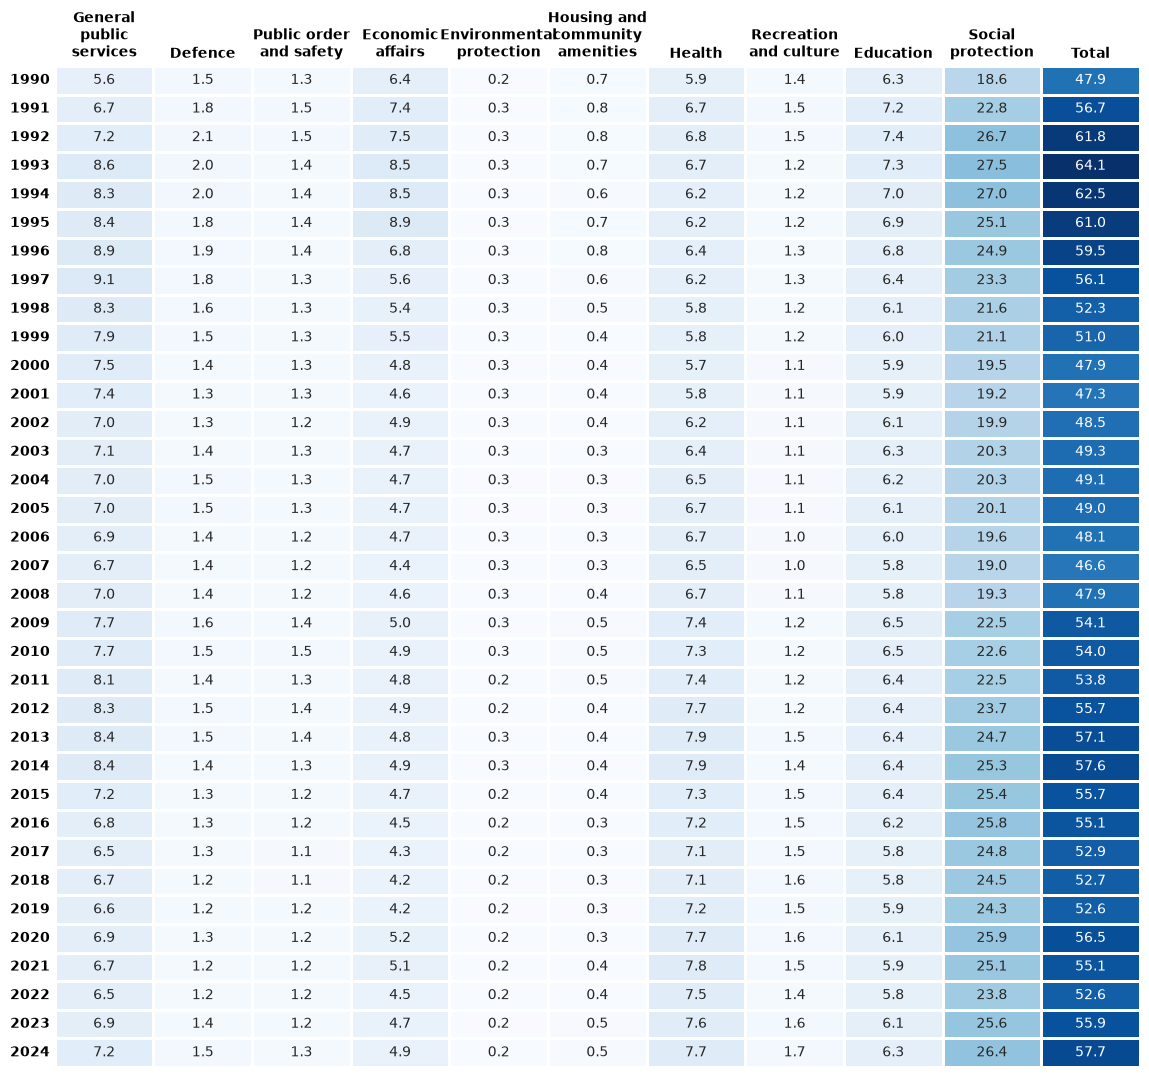

In [18]:
import textwrap

table = df.pivot(index="Year", columns="Function", values="Share of GDP, %")
order = list(functions.values())[1:] + ["Total"]
table = table[order]

plt.figure(figsize=(14, 13))
ax = sns.heatmap(table, cmap="Blues", annot=True, fmt=".1f", cbar=False,
                 linewidths=1, linecolor="white", annot_kws={"size": 10})
ax.xaxis.tick_top()
ax.set_xticklabels([textwrap.fill(name, 13) for name in table.columns], rotation=0, fontweight="bold")
ax.set_yticklabels(table.index, rotation=0, fontweight="bold")
ax.tick_params(length=0)
plt.xlabel("")
plt.ylabel("")
plt.show()

---

## 2. Total level of expenditure

Let's look at how total public expenditure relative to GDP has developed over 1990–2024.

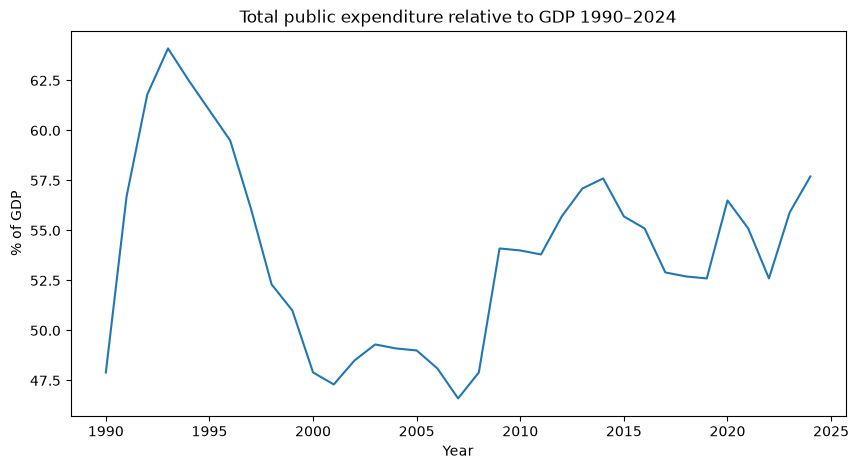

In [19]:
plt.figure(figsize=(10, 5))
plt.plot(table.index, table["Total"])
plt.title("Total public expenditure relative to GDP 1990–2024")
plt.xlabel("Year")
plt.ylabel("% of GDP")
plt.show()

The chart shows that the share of public expenditure in GDP has varied considerably over 1990–2024. The largest increases coincide with well-known economic crises:

- Early 1990s: the share rose from 47.9% (1990) to 64.1% (1993), the highest level of the whole period. At the same time, Finland was in a deep recession.
- 2000s: the share fell to around 47–48%. The lowest level was in 2007 (46.6%).
- 2009: the share rose quickly to 54.1%, at the same time as the global financial crisis. It stayed high and continued to grow in the early 2010s.
- 2020: the chart shows a new rise (56.5%) during the COVID-19 pandemic, after which the share fell for a while.
- 2024: the share has risen again to almost 58%.

The data does not directly tell us what causes the increases. A likely explanation is that when the economy is weak, GDP shrinks and, for example, unemployment expenditure grows, which raises the share of expenditure in GDP.

---

## 3. Comparison of expenditure items

Next, we compare how the share of GDP of the different expenditure items changed from 1990 to 2024.

In [20]:
def calculate_change(function):
    ''' Calculates the change in an expenditure item from 1990 to 2024. '''
    start = table.loc[1990, function]
    end = table.loc[2024, function]
    return round(end - start, 1)


print(calculate_change("Social protection"))

7.8


Use the function to calculate the change for all expenditure items and sort them from smallest to largest.

In [21]:
changes = {}
for function in order[:-1]:
    changes[function] = calculate_change(function)

changes = pd.Series(changes).sort_values()
changes

Economic affairs                  -1.5
Housing and community amenities   -0.2
Defence                            0.0
Public order and safety            0.0
Environmental protection           0.0
Education                          0.0
Recreation and culture             0.3
General public services            1.6
Health                             1.8
Social protection                  7.8
dtype: float64

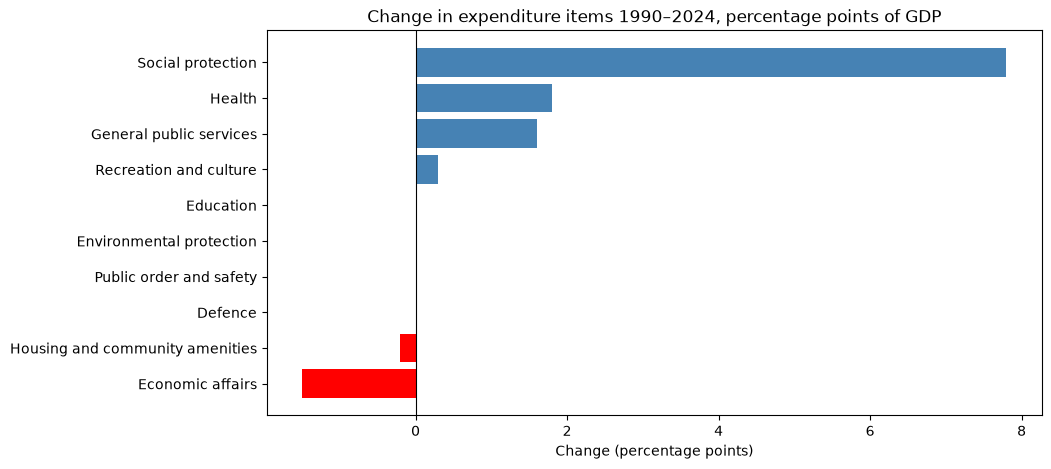

In [22]:
colors = ["red" if value < 0 else "steelblue" for value in changes]

plt.figure(figsize=(10, 5))
plt.barh(changes.index, changes.values, color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Change in expenditure items 1990–2024, percentage points of GDP")
plt.xlabel("Change (percentage points)")
plt.show()

The chart shows that the growth of public expenditure relative to GDP has been concentrated almost entirely in a few expenditure items:

- Social protection grew clearly the most, by 7.8 percentage points (18.6% → 26.4% of GDP).
- Health (+1.8) and general public services (+1.6) also grew.
- Economic affairs decreased the most (−1.5). The share of housing and community amenities also decreased slightly.
- The share of GDP of education, defence, public order and safety, and environmental protection is the same in 2024 as in 1990.

When the changes are added up, the result is about 9.8 percentage points, which corresponds to the growth of total public expenditure from 47.9% to about 57.7%.

### Expenditure items as objects

Each expenditure item is made into an object that has a name and a share of GDP in 1990 and 2024.

In [23]:
class ExpenditureItem:
    def __init__(self, name, start, end):
        self.name = name      # name of the expenditure item
        self.start = start    # share of GDP in 1990
        self.end = end        # share of GDP in 2024

    def print_change(self):
        change = round(self.end - self.start, 1)
        print(f"{self.name}: {self.start}% → {self.end}% (change {change:+} percentage points)")


# Create objects for three expenditure items:
social_protection = ExpenditureItem("Social protection", table.loc[1990, "Social protection"], table.loc[2024, "Social protection"])
health = ExpenditureItem("Health", table.loc[1990, "Health"], table.loc[2024, "Health"])
economic_affairs = ExpenditureItem("Economic affairs", table.loc[1990, "Economic affairs"], table.loc[2024, "Economic affairs"])

social_protection.print_change()
health.print_change()
economic_affairs.print_change()

Social protection: 18.6% → 26.4% (change +7.8 percentage points)
Health: 5.9% → 7.7% (change +1.8 percentage points)
Economic affairs: 6.4% → 4.9% (change -1.5 percentage points)


---

## 4. Conclusions

Answer to the main question: the share of Finnish public expenditure in GDP grew by about 10 percentage points between 1990 and 2024. The growth has been concentrated almost entirely in social protection, which has clearly been the largest expenditure item throughout the period. The shares of health and general public services have also grown, while relatively less is now spent on economic affairs than in the early 1990s.

Key findings:
- The share of expenditure in GDP rises clearly during economic crises.
- Social protection is clearly the largest expenditure item throughout the period, and its share of GDP grew the most (+7.8 percentage points). One possible explanation for this could be population ageing.
- The share of GDP of many expenditure items, such as education and defence, has remained almost unchanged.

Limitations: the share of expenditure in GDP also depends on how GDP develops. When the economy shrinks, the share of expenditure grows even if the amount in euros stays the same. The latest figures may still be revised when Statistics Finland updates the statistics.